In [3]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))
import pandas as pd
import matplotlib.pyplot as plt
import config
import quality as qa
from features import dataset_build as db

plt.style.use("seaborn-v0_8-whitegrid")

COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
NEUTRAL = "#c9c8c3"

print(f"Region: {config.PROCESSING_REGION} | years: {config.PROCESSING_YEARS}")

Region: southeast_asia | years: [2020, 2021, 2022, 2023, 2024, 2025]


In [4]:
missing = qa.missing_values()
missing

,rows
year,
2020,5996178
2021,5979795
2022,5979795
2023,5979795
2024,5996178
2025,5979795


In [5]:
qa.duplicate_keys()

,year,rows,repeated_keys,rows_from_other_years
0,2020,5996178,0,0
1,2021,5979795,0,0
2,2022,5979795,0,0
3,2023,5979795,0,0
4,2024,5996178,0,0
5,2025,5979795,0,0


In [6]:
problems = qa.rule_problems()
print(f"Rule violations over all years: {len(problems)}")
problems

Rule violations over all years: 0


,year,problem


In [7]:
landcover_cells = pd.read_parquet(config.PROCESSED_FILES["landcover_cells"])
cell_countries = db.load_cell_countries()

low_coverage = landcover_cells[landcover_cells["landcover_coverage_pct"] < 50]
low_coverage[["grid_id", "landcover_coverage_pct"]].merge(cell_countries[["grid_id", "country", "in_study_area"]], on="grid_id")

,grid_id,landcover_coverage_pct,country,in_study_area
0,28.5_109.5,26.6,CHN,0
1,28.5_92.0,29.0,CHN,0


In [8]:
by_country = qa.cells_by_country(cell_countries)
by_country

,country,cells,in_study_area,share_pct
0,CHN,7240,0,28.2
1,MMR,5787,1,22.5
2,THA,4331,1,16.8
3,VNM,2801,1,10.9
4,LAO,1956,1,7.6
5,IND,1758,0,6.8
6,KHM,1508,1,5.9
7,MYS,156,0,0.6
8,BGD,147,0,0.6
9,IDN,13,0,0.1


In [9]:
method_counts = cell_countries["country_method"].value_counts()
n_in = int(cell_countries["in_study_area"].sum())
print(f"Cells: {len(cell_countries):,}  |  in the study countries: {n_in:,} ({n_in / len(cell_countries) * 100:.1f}%)")
print(f"Country method: {method_counts.to_dict()}")

Cells: 25,704  |  in the study countries: 16,383 (63.7%)
Country method: {'inside': 25525, 'nearest': 177, 'none': 2}


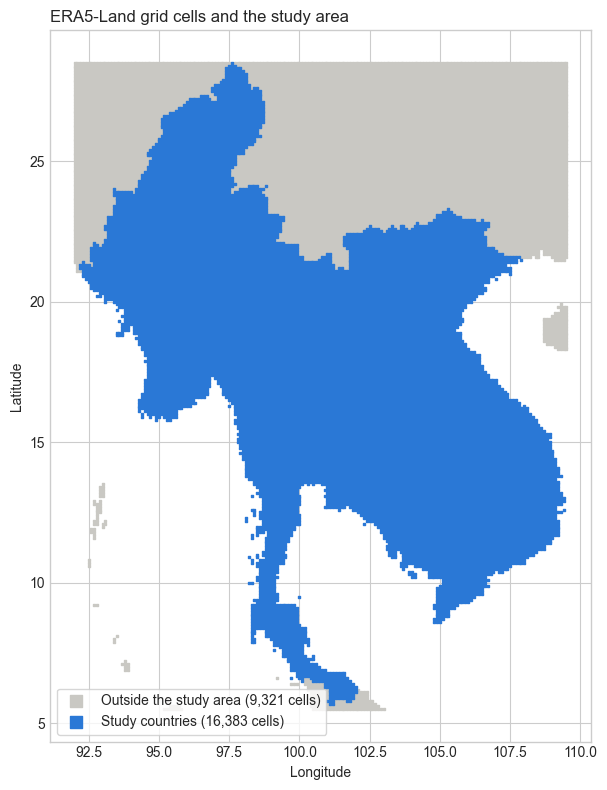

In [10]:
inside = cell_countries[cell_countries["in_study_area"] == 1]
outside = cell_countries[cell_countries["in_study_area"] == 0]

fig, ax = plt.subplots(figsize=(7, 8))
ax.scatter(outside["longitude"], outside["latitude"], s=1, marker="s", color=NEUTRAL, label=f"Outside the study area ({len(outside):,} cells)")
ax.scatter(inside["longitude"], inside["latitude"], s=1, marker="s", color=COLOURS[0], label=f"Study countries ({len(inside):,} cells)")
ax.set_title("ERA5-Land grid cells and the study area", loc="left")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
ax.legend(loc="lower left", markerscale=8, frameon=True)
plt.tight_layout()
plt.show()

In [11]:
consistency = qa.hotspot_vs_cell_country(cell_countries)
fire_days_total = int(consistency["fire_cell_days"].sum())
lost = consistency[~consistency["cell_country"].isin(config.STUDY_COUNTRIES)]
lost_days = int(lost["fire_cell_days"].sum())

keys = qa.duplicate_keys()
rows_kept = int(keys["rows"].sum())
days = rows_kept // n_in
rows_removed = len(outside) * days

print(f"Rows kept:    {rows_kept:,}  ({n_in:,} cells x {days:,} days)")
print(f"Rows removed: {rows_removed:,}  ({len(outside):,} cells x {days:,} days)")
print(f"Fire cell-days removed: {lost_days:,} of {fire_days_total:,} ({lost_days / fire_days_total * 100:.2f}%)")

Rows kept:    35,911,536  (16,383 cells x 2,192 days)
Rows removed: 20,431,632  (9,321 cells x 2,192 days)
Fire cell-days removed: 2,603 of 1,665,011 (0.16%)


In [12]:
checks = [
    ("rainfall_mm", True),
    ("temp_max_c", False),
    ("temp_max_c", True),
    ("wind_speed_kmh", True),
    ("dry_days", True),
    ("frp_max", True),
]

rows = []
for column, largest in checks:
    top = qa.extremes(column, n=1, largest=largest).iloc[0]
    rows.append({
        "check": f"{'highest' if largest else 'lowest'} {column}",
        "value": round(float(top[column]), 1),
        "grid_id": top["grid_id"],
        "date": top["date"].date(),
        "country": top["country"],
    })

extreme_table = pd.DataFrame(rows)
extreme_table

,check,value,grid_id,date,country
0,highest rainfall_mm,617.9,18.1_106.3,2020-10-20,VNM
1,lowest temp_max_c,-17.4,28.5_97.6,2022-01-17,MMR
2,highest temp_max_c,46.8,8.1_98.8,2020-05-16,THA
3,highest wind_speed_kmh,62.7,21.0_107.5,2024-09-07,VNM
4,highest dry_days,197.0,20.3_94.8,2023-05-11,MMR
5,highest frp_max,2317.4,22.4_99.2,2020-03-24,MMR


In [13]:
print("Highest daily rainfall, 20 October 2020:")
print(qa.compare_with_neighbours("18.1_106.3", "2020-10-20", "rainfall_mm").to_string(index=False))
print()
print("Highest daily maximum temperature, 16 May 2020:")
print(qa.compare_with_neighbours("8.1_98.8", "2020-05-16", "temp_max_c").to_string(index=False))

Highest daily rainfall, 20 October 2020:
   grid_id  is_checked_cell  rainfall_mm
18.0_106.2            False       453.11
18.0_106.3            False       541.52
18.0_106.4            False       553.61
18.1_106.2            False       484.82
18.1_106.3             True       617.95
18.1_106.4            False       586.93
18.2_106.2            False       517.06
18.2_106.3            False          NaN
18.2_106.4            False          NaN

Highest daily maximum temperature, 16 May 2020:
 grid_id  is_checked_cell  temp_max_c
8.0_98.7            False         NaN
8.0_98.8            False         NaN
8.0_98.9            False         NaN
8.1_98.7            False         NaN
8.1_98.8             True       46.81
8.1_98.9            False       33.90
8.2_98.7            False         NaN
8.2_98.8            False       33.36
8.2_98.9            False       33.88


In [14]:
same = int(consistency.loc[consistency["same_country"], "fire_cell_days"].sum())
print(f"Fire cell-days where both agree: {same:,} of {fire_days_total:,} ({same / fire_days_total * 100:.1f}%)")
consistency[~consistency["same_country"]].head(8)

Fire cell-days where both agree: 1,646,284 of 1,665,011 (98.9%)


,hotspot_country,cell_country,fire_cell_days,same_country
5,MMR,THA,2435,False
6,LAO,THA,2402,False
7,KHM,THA,1695,False
8,LAO,VNM,1661,False
9,THA,MMR,1629,False
10,VNM,KHM,1121,False
11,MMR,IND,1109,False
12,VNM,LAO,1106,False


In [15]:
volume = qa.counts_by_country_year(cell_countries=cell_countries)
volume.pivot(index="country", columns="year", values="fire_days_per_cell")

year,2020,2021,2022,2023,2024,2025
country,,,,,,
KHM,38.27,30.83,18.66,26.74,32.91,24.09
LAO,22.86,18.52,16.54,32.28,25.26,18.79
MMR,21.93,18.45,13.70,21.61,18.08,15.54
THA,19.74,11.93,7.43,16.16,14.00,10.17
VNM,11.78,10.07,7.51,10.48,10.74,8.21


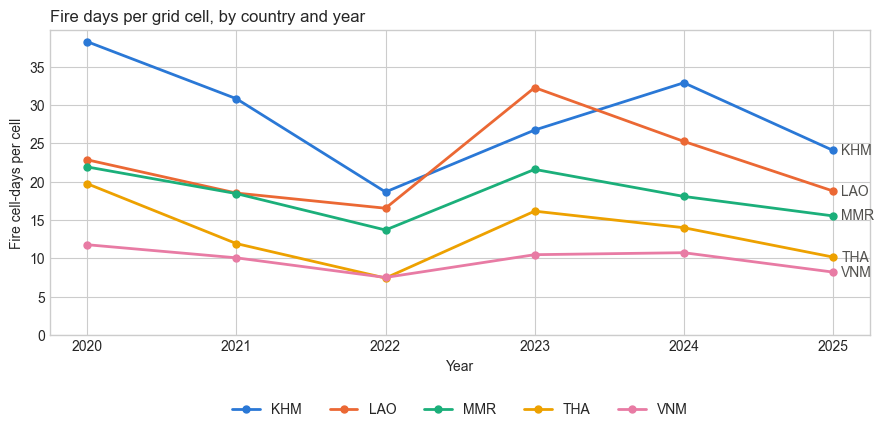

In [16]:
pivot = volume.pivot(index="year", columns="country", values="fire_days_per_cell")
countries = pivot.iloc[-1].sort_values(ascending=False).index.tolist()

fig, ax = plt.subplots(figsize=(9, 4.5))
for number, country in enumerate(countries):
    ax.plot(pivot.index, pivot[country], color=COLOURS[number], linewidth=2, marker="o", markersize=5, label=country)
    ax.annotate(country, (pivot.index[-1], pivot[country].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=10, color="#52514e")
ax.set_title("Fire days per grid cell, by country and year", loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Fire cell-days per cell")
ax.set_xticks(pivot.index)
ax.set_ylim(bottom=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=5, frameon=False)
plt.tight_layout()
plt.show()

Hotspots: 5,030,113 | latitude 5.69 to 28.25, longitude 92.20 to 109.43
Countries: ['KHM', 'LAO', 'MMR', 'THA', 'VNM']


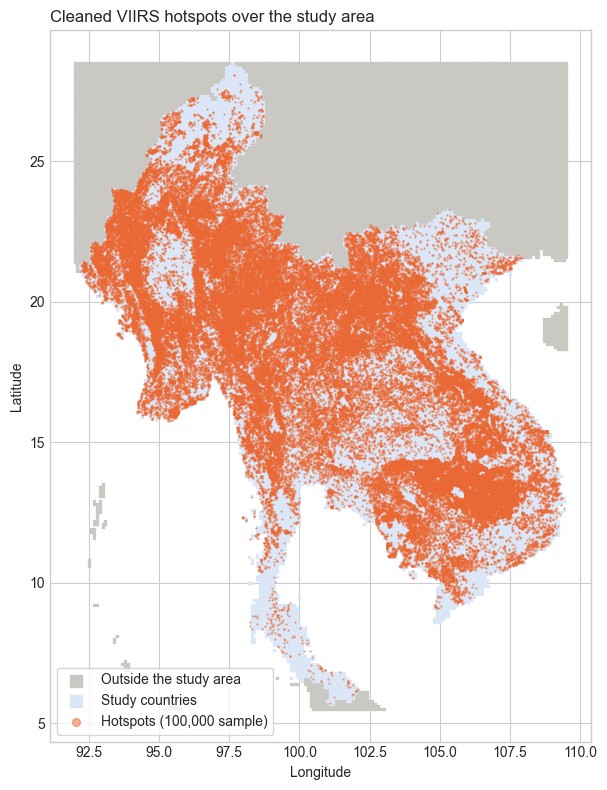

In [17]:
firms = pd.read_parquet(config.PROCESSED_FILES["firms_clean"], columns=["latitude", "longitude", "country"])
print(f"Hotspots: {len(firms):,} | latitude {firms['latitude'].min():.2f} to {firms['latitude'].max():.2f}, "
      f"longitude {firms['longitude'].min():.2f} to {firms['longitude'].max():.2f}")
print(f"Countries: {sorted(firms['country'].unique().tolist())}")
hotspot_sample = firms.sample(n=100_000, random_state=0)
del firms

fig, ax = plt.subplots(figsize=(7, 8))
ax.scatter(outside["longitude"], outside["latitude"], s=1, marker="s", color=NEUTRAL, label="Outside the study area")
ax.scatter(inside["longitude"], inside["latitude"], s=1, marker="s", color="#dbe7f7", label="Study countries")
ax.scatter(hotspot_sample["longitude"], hotspot_sample["latitude"], s=0.5, color=COLOURS[1], alpha=0.5, label="Hotspots (100,000 sample)")
ax.set_title("Cleaned VIIRS hotspots over the study area", loc="left")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
ax.legend(loc="lower left", markerscale=8, frameon=True)
plt.tight_layout()
plt.show()